# Clasificación Binaria

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Importing Libraries

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedShuffleSplit

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
#from keras.wrappers.scikit_learn import KerasClassifier
from xgboost import XGBClassifier

from sklearn.metrics import mean_absolute_error, accuracy_score, classification_report, confusion_matrix

In [4]:
# Setting the numpy random seed

np.random.seed(37)

In [7]:
# Loading Dataset

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Clasificación/attrition_data.csv')
print('Dataframe shape: ', df.shape)

Dataframe shape:  (9612, 27)


In [8]:
df.size

259524

In [9]:
df.shape[0]*df.shape[1]

259524

In [11]:
df.head()

,EMP_ID,ANNUAL_RATE,HRLY_RATE,JOBCODE,ETHNICITY,SEX,MARITAL_STATUS,JOB_SATISFACTION,AGE,NUMBER_OF_TEAM_CHANGED,...,DISABLED_EMP,DISABLED_VET,EDUCATION_LEVEL,STATUS,JOB_GROUP,PREVYR_1,PREVYR_2,PREVYR_3,PREVYR_4,PREVYR_5
0,3285941608,33615,22,71850,BLACK,F,Divorced,4,35,3+,...,N,N,LEVEL 2,T,Plant & Facilities Maintenance,0,0,0,0,0
1,3687079832,70675,40,59806,ASIAN,M,Single,3,18,3+,...,N,N,LEVEL 1,A,Customer Care,3,3,3,2,3
2,7209970080,34320,23,60311,WHITE,F,Single,5,18,2,...,N,N,LEVEL 1,A,Customer Care,3,3,3,2,3
3,9084013977,103199,59,16233,ASIAN,F,Single,2,50,0,...,N,N,LEVEL 1,T,Finance,0,0,0,0,0
4,4566148978,141801,71,64415,ASIAN,F,Single,4,34,3,...,N,N,LEVEL 1,A,Marketing - Direct,2,2,2,2,2


In [10]:
df.columns.to_list()

['EMP_ID',
 'ANNUAL_RATE',
 'HRLY_RATE',
 'JOBCODE',
 'ETHNICITY',
 'SEX',
 'MARITAL_STATUS',
 'JOB_SATISFACTION',
 'AGE',
 'NUMBER_OF_TEAM_CHANGED',
 'REFERRAL_SOURCE',
 'HIRE_MONTH',
 'REHIRE',
 'TERMINATION_YEAR',
 'IS_FIRST_JOB',
 'TRAVELLED_REQUIRED',
 'PERFORMANCE_RATING',
 'DISABLED_EMP',
 'DISABLED_VET',
 'EDUCATION_LEVEL',
 'STATUS',
 'JOB_GROUP',
 'PREVYR_1',
 'PREVYR_2',
 'PREVYR_3',
 'PREVYR_4',
 'PREVYR_5']

In [12]:
len(df.columns.to_list())

27

Esta base de datos recopila información demográfica, laboral y de desempeño de empleados de una organización con el objetivo de analizar patrones asociados a la deserción laboral (attrition). Cada fila representa a un empleado, identificado de forma única por un código (EMP_ID), y está caracterizado por una serie de variables que incluyen aspectos salariales, satisfacción laboral, desempeño, historial de movilidad interna, condiciones personales y laborales.

In [13]:
df.STATUS.unique()

array(['T', 'A'], dtype=object)

In [14]:
df["STATUS"].unique()

array(['T', 'A'], dtype=object)

### Descripción de variables - Base de datos de Attrition

| Variable                  | Descripción                                                                 |
|---------------------------|-----------------------------------------------------------------------------|
| `EMP_ID`                 | Identificador único del empleado.                                           |
| `ANNUAL_RATE`            | Salario anual del empleado.                                                 |
| `HRLY_RATE`              | Salario por hora del empleado.                                              |
| `JOBCODE`                | Código que identifica el cargo u ocupación del empleado.                    |
| `ETHNICITY`              | Grupo étnico declarado del empleado.                                        |
| `SEX`                    | Sexo del empleado (por ejemplo: M/F).                                       |
| `MARITAL_STATUS`         | Estado civil del empleado (casado, soltero, etc.).                          |
| `JOB_SATISFACTION`       | Nivel de satisfacción laboral reportado por el empleado (escala ordinal).   |
| `AGE`                    | Edad del empleado.                                                          |
| `NUMBER_OF_TEAM_CHANGED` | Número de veces que el empleado ha cambiado de equipo.                      |
| `REFERRAL_SOURCE`        | Fuente a través de la cual se vinculó el empleado (recomendación, portal, etc.). |
| `HIRE_MONTH`             | Mes en el que fue contratado el empleado.                                   |
| `REHIRE`                 | Indicador de si el empleado fue recontratado.                               |
| `TERMINATION_YEAR`       | Año en el que se terminó su contrato (si aplica).                           |
| `IS_FIRST_JOB`           | Indicador de si es el primer trabajo del empleado.                          |
| `TRAVELLED_REQUIRED`     | Indicador de si el puesto requiere viajes.                                  |
| `PERFORMANCE_RATING`     | Calificación de desempeño del empleado (ordinal o numérica).                |
| `DISABLED_EMP`           | Indicador de discapacidad del empleado.                                     |
| `DISABLED_VET`           | Indicador de si el empleado es veterano discapacitado.                      |
| `EDUCATION_LEVEL`        | Nivel educativo alcanzado (por ejemplo: secundaria, pregrado, posgrado).    |
| `STATUS`                 | Estado laboral del empleado (por ejemplo: Activo 'A' o Terminado 'T').      |
| `JOB_GROUP`              | Agrupación o clasificación del tipo de trabajo realizado.                   |
| `PREVYR_1` a `PREVYR_5`  | Métricas de desempeño o evaluaciones de años anteriores.                    |



## Limpieza de datos

In [15]:
df.head()

,EMP_ID,ANNUAL_RATE,HRLY_RATE,JOBCODE,ETHNICITY,SEX,MARITAL_STATUS,JOB_SATISFACTION,AGE,NUMBER_OF_TEAM_CHANGED,...,DISABLED_EMP,DISABLED_VET,EDUCATION_LEVEL,STATUS,JOB_GROUP,PREVYR_1,PREVYR_2,PREVYR_3,PREVYR_4,PREVYR_5
0,3285941608,33615,22,71850,BLACK,F,Divorced,4,35,3+,...,N,N,LEVEL 2,T,Plant & Facilities Maintenance,0,0,0,0,0
1,3687079832,70675,40,59806,ASIAN,M,Single,3,18,3+,...,N,N,LEVEL 1,A,Customer Care,3,3,3,2,3
2,7209970080,34320,23,60311,WHITE,F,Single,5,18,2,...,N,N,LEVEL 1,A,Customer Care,3,3,3,2,3
3,9084013977,103199,59,16233,ASIAN,F,Single,2,50,0,...,N,N,LEVEL 1,T,Finance,0,0,0,0,0
4,4566148978,141801,71,64415,ASIAN,F,Single,4,34,3,...,N,N,LEVEL 1,A,Marketing - Direct,2,2,2,2,2


In [17]:
True #1
False #0

False

In [16]:
# Checking for missing values

df.isnull().sum()

,0
EMP_ID,0
ANNUAL_RATE,0
HRLY_RATE,0
JOBCODE,0
ETHNICITY,0
SEX,0
MARITAL_STATUS,0
JOB_SATISFACTION,0
AGE,0
NUMBER_OF_TEAM_CHANGED,0


In [18]:
# Dropping irrelevant columns

df.drop(['EMP_ID', 'JOBCODE', 'TERMINATION_YEAR'], axis=1, inplace=True)
df.drop(df.iloc[:, -5:], axis=1, inplace=True)

In [19]:
df.columns.to_list()

['ANNUAL_RATE',
 'HRLY_RATE',
 'ETHNICITY',
 'SEX',
 'MARITAL_STATUS',
 'JOB_SATISFACTION',
 'AGE',
 'NUMBER_OF_TEAM_CHANGED',
 'REFERRAL_SOURCE',
 'HIRE_MONTH',
 'REHIRE',
 'IS_FIRST_JOB',
 'TRAVELLED_REQUIRED',
 'PERFORMANCE_RATING',
 'DISABLED_EMP',
 'DISABLED_VET',
 'EDUCATION_LEVEL',
 'STATUS',
 'JOB_GROUP']

In [20]:
df['REFERRAL_SOURCE'].fillna(df['REFERRAL_SOURCE'].mode()[0], inplace=True)

In [21]:
df.head()

,ANNUAL_RATE,HRLY_RATE,ETHNICITY,SEX,MARITAL_STATUS,JOB_SATISFACTION,AGE,NUMBER_OF_TEAM_CHANGED,REFERRAL_SOURCE,HIRE_MONTH,REHIRE,IS_FIRST_JOB,TRAVELLED_REQUIRED,PERFORMANCE_RATING,DISABLED_EMP,DISABLED_VET,EDUCATION_LEVEL,STATUS,JOB_GROUP
0,33615,22,BLACK,F,Divorced,4,35,3+,Client Referral,June,False,N,N,4,N,N,LEVEL 2,T,Plant & Facilities Maintenance
1,70675,40,ASIAN,M,Single,3,18,3+,Executive Referral,June,False,Y,N,3,N,N,LEVEL 1,A,Customer Care
2,34320,23,WHITE,F,Single,5,18,2,Former Employee/Intern,February,False,Y,N,3,N,N,LEVEL 1,A,Customer Care
3,103199,59,ASIAN,F,Single,2,50,0,Direct Sourcing,October,True,N,Y,2,N,N,LEVEL 1,T,Finance
4,141801,71,ASIAN,F,Single,4,34,3,Inroads,May,False,N,N,4,N,N,LEVEL 1,A,Marketing - Direct


In [23]:
df.shape

(9612, 19)

In [22]:
df.isnull().sum()

,0
ANNUAL_RATE,0
HRLY_RATE,0
ETHNICITY,0
SEX,0
MARITAL_STATUS,0
JOB_SATISFACTION,0
AGE,0
NUMBER_OF_TEAM_CHANGED,0
REFERRAL_SOURCE,0
HIRE_MONTH,0


## Visualizaciones

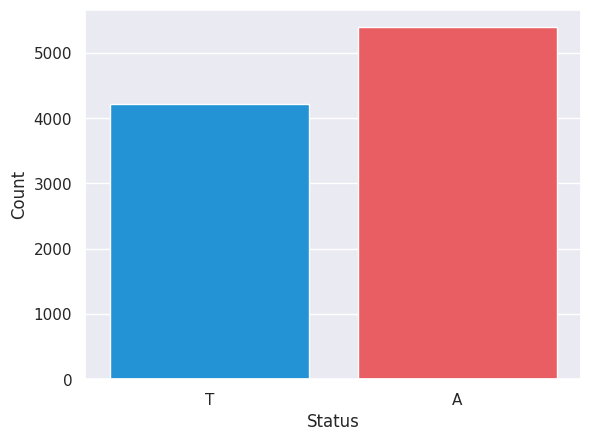

In [24]:
sns.set(style="darkgrid")
ax = sns.countplot(x="STATUS", data=df, palette=sns.xkcd_palette(["azure", "light red"]))
plt.xlabel('Status')
plt.ylabel('Count')
#plt.savefig('./plots/status_count.png')
plt.show()

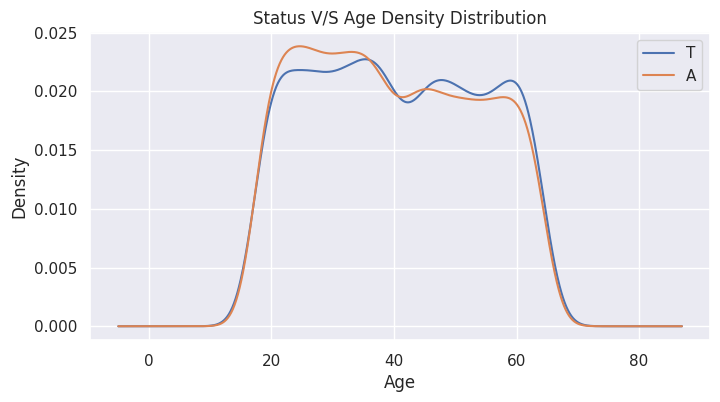

In [25]:
fig=plt.figure(figsize=(8,4))
for x in ['T','A']:
    df['AGE'][df['STATUS']==x].plot(kind='kde')

plt.title('Status V/S Age Density Distribution')
plt.legend(('T','A'))
plt.xlabel('Age')
#plt.savefig('./plots/status_age_distribution.png')
plt.show()

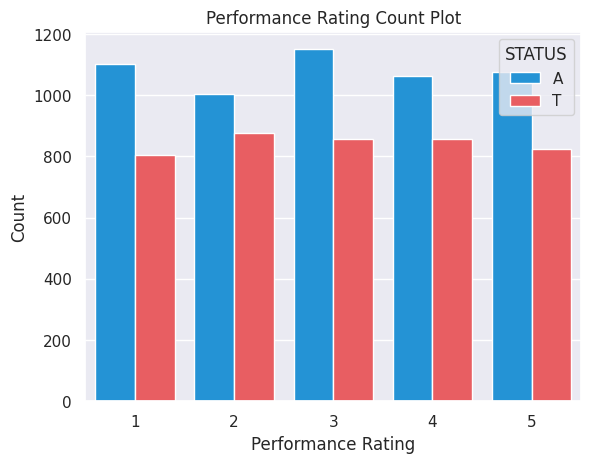

In [26]:
sns.countplot(x='PERFORMANCE_RATING', data=df, hue='STATUS', palette=sns.xkcd_palette(["azure", "light red"]))
plt.title("Performance Rating Count Plot")
plt.xlabel('Performance Rating')
plt.ylabel('Count')
#plt.savefig('./plots/performance_count.png')
plt.show()

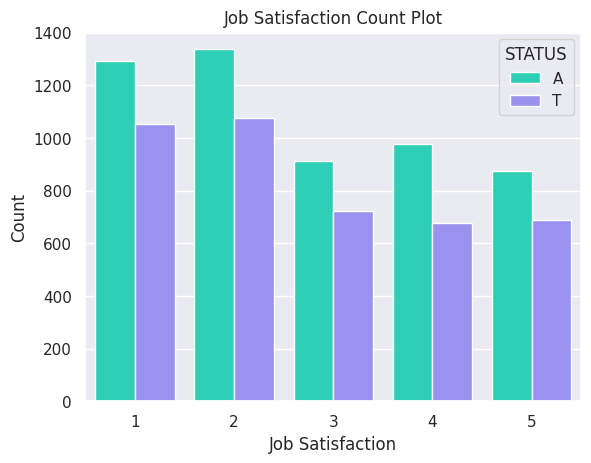

In [27]:
sns.countplot(x='JOB_SATISFACTION', data=df, hue='STATUS', palette=sns.xkcd_palette(["aqua", "periwinkle"]))
plt.title("Job Satisfaction Count Plot")
plt.xlabel('Job Satisfaction')
plt.ylabel('Count')
#plt.savefig('./plots/satisfaction_count.png')
plt.show()

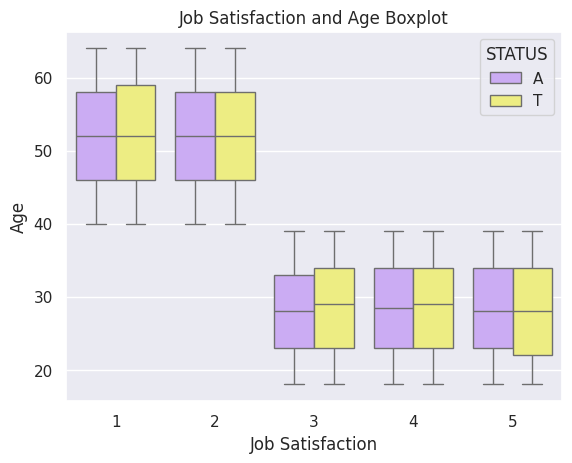

In [28]:
sns.boxplot(x='JOB_SATISFACTION',data=df,hue='STATUS',y='AGE', palette=sns.xkcd_palette(["pastel purple", "pastel yellow"]))
plt.title("Job Satisfaction and Age Boxplot")
plt.xlabel('Job Satisfaction')
plt.ylabel('Age')
#plt.savefig('./plots/age_satisfaction_box.png')
plt.show()

## Ajustando Columnas (Convirtiendo a Número)

In [29]:
# Label Encoding categorical features

le = LabelEncoder()
df['NUMBER_OF_TEAM_CHANGED'] = le.fit_transform(df['NUMBER_OF_TEAM_CHANGED'])
df['REHIRE'] = le.fit_transform(df['REHIRE'])
df['IS_FIRST_JOB'] = le.fit_transform(df['IS_FIRST_JOB'])
df['TRAVELLED_REQUIRED'] = le.fit_transform(df['TRAVELLED_REQUIRED'])
df['DISABLED_EMP'] = le.fit_transform(df['DISABLED_EMP'])
df['DISABLED_VET'] = le.fit_transform(df['DISABLED_VET'])
df['EDUCATION_LEVEL'] = le.fit_transform(df['EDUCATION_LEVEL'])
df['STATUS'] = le.fit_transform(df['STATUS'])

In [30]:
df.columns

Index(['ANNUAL_RATE', 'HRLY_RATE', 'ETHNICITY', 'SEX', 'MARITAL_STATUS',
       'JOB_SATISFACTION', 'AGE', 'NUMBER_OF_TEAM_CHANGED', 'REFERRAL_SOURCE',
       'HIRE_MONTH', 'REHIRE', 'IS_FIRST_JOB', 'TRAVELLED_REQUIRED',
       'PERFORMANCE_RATING', 'DISABLED_EMP', 'DISABLED_VET', 'EDUCATION_LEVEL',
       'STATUS', 'JOB_GROUP'],
      dtype='object')

In [31]:
df.shape

(9612, 19)

In [32]:
df.NUMBER_OF_TEAM_CHANGED.unique()

array([4, 2, 0, 3, 1])

In [33]:
df.EDUCATION_LEVEL.unique()

array([1, 0, 2, 3, 4])

In [34]:
df.drop(['HRLY_RATE'], axis=1, inplace=True)

In [35]:
# One-Hot Encoding categorical features

df['HIRE_MONTH'] = df['HIRE_MONTH'].astype('category')
df['JOB_GROUP'] = df['JOB_GROUP'].astype('category')
df['REFERRAL_SOURCE'] = df['REFERRAL_SOURCE'].astype('category')
df['ETHNICITY'] = df['ETHNICITY'].astype('category')
df['SEX'] = df['SEX'].astype('category')
df['MARITAL_STATUS'] = df['MARITAL_STATUS'].astype('category')
df = pd.get_dummies(df, columns=['HIRE_MONTH', 'JOB_GROUP', 'REFERRAL_SOURCE', 'SEX', 'MARITAL_STATUS', 'ETHNICITY'])

In [38]:
# X = features & y = Target class

X = df.drop(['STATUS'], axis=1)
y = df['STATUS']

In [39]:
X

,ANNUAL_RATE,JOB_SATISFACTION,AGE,NUMBER_OF_TEAM_CHANGED,REHIRE,IS_FIRST_JOB,TRAVELLED_REQUIRED,PERFORMANCE_RATING,DISABLED_EMP,DISABLED_VET,...,MARITAL_STATUS_Married,MARITAL_STATUS_Single,ETHNICITY_,ETHNICITY_AMIND,ETHNICITY_ASIAN,ETHNICITY_BLACK,ETHNICITY_HISPA,ETHNICITY_PACIF,ETHNICITY_TWO,ETHNICITY_WHITE
0,33615,4,35,4,0,0,0,4,0,0,...,False,False,False,False,False,True,False,False,False,False
1,70675,3,18,4,0,1,0,3,0,0,...,False,True,False,False,True,False,False,False,False,False
2,34320,5,18,2,0,1,0,3,0,0,...,False,True,False,False,False,False,False,False,False,True
3,103199,2,50,0,1,0,1,2,0,0,...,False,True,False,False,True,False,False,False,False,False
4,141801,4,34,3,0,0,0,4,0,0,...,False,True,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9607,34636,1,43,0,0,0,0,1,0,1,...,False,True,False,False,True,False,False,False,False,False
9608,34962,5,28,2,0,0,0,1,0,0,...,False,True,False,False,False,False,False,False,False,True
9609,39286,3,31,2,0,0,0,1,0,0,...,False,True,False,False,False,False,False,False,False,True
9610,39145,4,32,4,0,0,0,4,0,0,...,True,False,False,False,False,False,False,False,False,True


In [40]:
y

,STATUS
0,1
1,0
2,0
3,1
4,0
...,...
9607,0
9608,0
9609,0
9610,0


In [41]:
# Normalizing the all the features

scaler = StandardScaler()

X = scaler.fit_transform(X)

In [42]:
df.shape[0]*0.7

6728.4

In [43]:
# Splitting dataset into training and testing split with 70-30% ratio

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [44]:
# K-fold splits

cv = StratifiedShuffleSplit(n_splits=10, test_size=.30, random_state=15)

## Modelación

### Logistic Regression

In [45]:
# Building our model with K-fold validation and GridSearch to find the best parameters

# Defining all the parameters
params = {
    'penalty': ['l1','l2'],
    'C': [0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1,2,3,4,5,6,7,8,9,10]
}

# Building model
logreg = LogisticRegression(solver='liblinear')

# Parameter estimating using GridSearch
grid = GridSearchCV(logreg, param_grid=params, scoring='accuracy', n_jobs =-1, cv=cv, verbose=1)

# Fitting the model
grid.fit(X_train, y_train)

Fitting 10 folds for each of 36 candidates, totalling 360 fits


GridSearchCV(cv=StratifiedShuffleSplit(n_splits=10, random_state=15, test_size=0.3,
            train_size=None),
             estimator=LogisticRegression(solver='liblinear'), n_jobs=-1,
             param_grid={'C': [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 2, 3,
                               4, 5, 6, 7, 8, 9, 10],
                         'penalty': ['l1', 'l2']},
             scoring='accuracy', verbose=1)

In [46]:
print('Best Score:', grid.best_score_)
print('Best Params:', grid.best_params_)
print('Best Estimator:', grid.best_estimator_)

Best Score: 0.6856859831599802
Best Params: {'C': 0.2, 'penalty': 'l1'}
Best Estimator: LogisticRegression(C=0.2, penalty='l1', solver='liblinear')


In [47]:
# Using the best parameters from the grid-search and predicting on test feature dataset(X_test)

logreg_grid = grid.best_estimator_
y_pred = logreg_grid.predict(X_test)

In [48]:
# Confusion matrix

pd.DataFrame(confusion_matrix(y_test,y_pred), columns=["Predicted A", "Predicted T"], index=["Actual A","Actual T"] )

,Predicted A,Predicted T
Actual A,1288,337
Actual T,516,743


In [49]:
# Calculating metrics

logreg_grid_score = accuracy_score(y_test, y_pred)
print('Model Accuracy:', logreg_grid_score)
print('Classification Report:\n', classification_report(y_test, y_pred))

Model Accuracy: 0.7042302357836339
Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.79      0.75      1625
           1       0.69      0.59      0.64      1259

    accuracy                           0.70      2884
   macro avg       0.70      0.69      0.69      2884
weighted avg       0.70      0.70      0.70      2884



In [50]:
rec_0=1288/(1288+337)
print(rec_0)

rec_1=743/(516+743)
print(rec_1)

preci_0=1288/(1288+516)
print(preci_0)

prec_1=743/(743+337)
print(prec_1)

acc=(1288+743)/(1288+743+337+516)
print(acc)

f1_0=2*(preci_0*rec_0/(preci_0+rec_0))
print(f1_0)

f1_1=2*(prec_1*rec_1/(prec_1+rec_1))
print(f1_1)

0.7926153846153846
0.5901509134233519
0.7139689578713969
0.687962962962963
0.7042302357836339
0.7512394284047827
0.6353142368533562


1288: Empleados que no se fueron y el modelo predijo correctamente que no se irían (¡bien!).

337: Empleados que no se fueron pero el modelo predijo que sí (falsas alarmas).

516: Empleados que sí se fueron pero el modelo no lo detectó (fallo serio).

743: Empleados que se fueron y el modelo los detectó correctamente (¡muy bien!).



rec_0 = 1288 / (1288 + 337) ≈ 79.26%

De todos los empleados que no se fueron, el modelo identificó correctamente al 79.26%.

rec_1 = 743 / (516 + 743) ≈ 59.00%

De todos los empleados que sí se fueron, el modelo identificó correctamente solo al 59%.


preci_0 = 1288 / (1288 + 516) ≈ 71.40%

De todos los empleados que el modelo predijo que no se irían, el 71.4% realmente no se fue.

prec_1 = 743 / (743 + 337) ≈ 68.79%

De todos los empleados que el modelo predijo que sí se irían, el 68.79% efectivamente se fue.

acc = (1288 + 743) / (1288 + 337 + 516 + 743) ≈ 75.67%

El modelo acierta en aproximadamente el 75.67% del total de casos.


### K-Nearest Neighbor Classifier(KNN)

In [51]:
# Building our model with K-fold validation and GridSearch to find the best parameters

# Defining all the parameters
params = {
    'n_neighbors': [3,5,11,19],
    'weights': ['uniform','distance']
}

# Building model
knn = KNeighborsClassifier()

# Parameter estimating using GridSearch
grid = GridSearchCV(knn, param_grid=params, scoring='accuracy', n_jobs =-1, cv=cv, verbose=1)

# Fitting the model
grid.fit(X_train, y_train)

Fitting 10 folds for each of 8 candidates, totalling 80 fits


GridSearchCV(cv=StratifiedShuffleSplit(n_splits=10, random_state=15, test_size=0.3,
            train_size=None),
             estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [3, 5, 11, 19],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy', verbose=1)

In [52]:
print('Best Score:', grid.best_score_)
print('Best Params:', grid.best_params_)
print('Best Estimator:', grid.best_estimator_)

Best Score: 0.6381376919266962
Best Params: {'n_neighbors': 19, 'weights': 'uniform'}
Best Estimator: KNeighborsClassifier(n_neighbors=19)


In [53]:
# Using the best parameters from the grid-search and predicting on test feature dataset(X_test)

knn_grid= grid.best_estimator_
y_pred = knn_grid.predict(X_test)

In [54]:
# Confusion matrix

pd.DataFrame(confusion_matrix(y_test,y_pred), columns=["Predicted A", "Predicted T"], index=["Actual A","Actual T"] )

,Predicted A,Predicted T
Actual A,1218,407
Actual T,603,656


In [55]:
# Calculating metrics

knn_grid_score = accuracy_score(y_test, y_pred)
print('Model Accuracy:', knn_grid_score)
print('Classification Report:\n', classification_report(y_test, y_pred))

Model Accuracy: 0.6497919556171984
Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.75      0.71      1625
           1       0.62      0.52      0.57      1259

    accuracy                           0.65      2884
   macro avg       0.64      0.64      0.64      2884
weighted avg       0.65      0.65      0.64      2884



### Gaussian Naive Bayes

In [56]:
# Building our model with K-fold validation and GridSearch to find the best parameters

# No such parameters for Gaussian Naive Bayes
params = {}

# Building model
gb = GaussianNB()

# Parameter estimating using GridSearch
grid = GridSearchCV(gb, param_grid=params, scoring='accuracy', n_jobs =-1, cv=cv, verbose=1)

# Fitting the model
grid.fit(X_train, y_train)

Fitting 10 folds for each of 1 candidates, totalling 10 fits


GridSearchCV(cv=StratifiedShuffleSplit(n_splits=10, random_state=15, test_size=0.3,
            train_size=None),
             estimator=GaussianNB(), n_jobs=-1, param_grid={},
             scoring='accuracy', verbose=1)

In [57]:
print('Best Score:', grid.best_score_)
print('Best Estimator:', grid.best_estimator_)

Best Score: 0.5548291233283804
Best Estimator: GaussianNB()


In [58]:
# Using the best parameters from the grid-search and predicting on test feature dataset(X_test)

gb_grid= grid.best_estimator_
y_pred = gb_grid.predict(X_test)

In [59]:
# Confusion matrix

pd.DataFrame(confusion_matrix(y_test,y_pred), columns=["Predicted A", "Predicted T"], index=["Actual A","Actual T"] )

,Predicted A,Predicted T
Actual A,1221,404
Actual T,581,678


In [60]:
# Calculating metrics

gb_grid_score = accuracy_score(y_test, y_pred)
print('Model Accuracy:', gb_grid_score)
print('Classification Report:\n', classification_report(y_test, y_pred))

Model Accuracy: 0.6584604715672677
Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.75      0.71      1625
           1       0.63      0.54      0.58      1259

    accuracy                           0.66      2884
   macro avg       0.65      0.64      0.65      2884
weighted avg       0.66      0.66      0.65      2884



### Support Vector Machines

In [61]:
# Building our model with K-fold validation and GridSearch to find the best parameters

# Defining all the parameters
params = {
    'C': [ 1, 10], ###0.001, 0.01, 0.1,
    'gamma' : [ 0.1, 1] #0.001,0.001, 0.01,
}

# Building model
svc = SVC(kernel='rbf', probability=True) ## 'rbf' stands for gaussian kernel

# Parameter estimating using GridSearch
grid = GridSearchCV(svc, param_grid=params, scoring='accuracy', n_jobs =-1, cv=cv, verbose=1)

# Fitting the model
grid.fit(X_train, y_train)

Fitting 10 folds for each of 4 candidates, totalling 40 fits


GridSearchCV(cv=StratifiedShuffleSplit(n_splits=10, random_state=15, test_size=0.3,
            train_size=None),
             estimator=SVC(probability=True), n_jobs=-1,
             param_grid={'C': [1, 10], 'gamma': [0.1, 1]}, scoring='accuracy',
             verbose=1)

In [ ]:
print('Best Score:', grid.best_score_)
print('Best Params:', grid.best_params_)
print('Best Estimator:', grid.best_estimator_)

In [ ]:
# Using the best parameters from the grid-search and predicting on test feature dataset(X_test)

svm_grid= grid.best_estimator_
y_pred = svm_grid.predict(X_test)

In [ ]:
# Confusion matrix

pd.DataFrame(confusion_matrix(y_test,y_pred), columns=["Predicted A", "Predicted T"], index=["Actual A","Actual T"] )

In [ ]:
# Calculating metrics

svm_grid_score = accuracy_score(y_test, y_pred)
print('Model Accuracy:', svm_grid_score)
print('Classification Report:\n', classification_report(y_test, y_pred))

### Decision Tree Classifier

In [ ]:
# Building our model with K-fold validation and GridSearch to find the best parameters

# Defining all the parameters
params = {
    'max_features': [1, 3, 10],
    'min_samples_split': [2, 3, 10],
    'min_samples_leaf': [1, 3, 10],
    'criterion': ["entropy", "gini"]
}

# Building model
dtc = DecisionTreeClassifier()

# Parameter estimating using GridSearch
grid = GridSearchCV(dtc, param_grid=params, scoring='accuracy', n_jobs =-1, cv=cv, verbose=1)

# Fitting the model
grid.fit(X_train, y_train)

In [ ]:
print('Best Score:', grid.best_score_)
print('Best Params:', grid.best_params_)
print('Best Estimator:', grid.best_estimator_)

In [ ]:
# Using the best parameters from the grid-search and predicting on test feature dataset(X_test)

dtc_grid= grid.best_estimator_
y_pred = dtc_grid.predict(X_test)

In [ ]:
# Confusion matrix

pd.DataFrame(confusion_matrix(y_test,y_pred), columns=["Predicted A", "Predicted T"], index=["Actual A","Actual T"] )

In [ ]:
# Calculating metrics

dtc_grid_score = accuracy_score(y_test, y_pred)
print('Model Accuracy:', dtc_grid_score)
print('Classification Report:\n', classification_report(y_test, y_pred))

### Random Forest Classifier

 #### No Ejecutar

In [ ]:
# Building our model with K-fold validation and GridSearch to find the best parameters

# Defining all the parameters
params = {
    'max_features': [1, 3, 10],
    'min_samples_split': [2, 3, 10],
    'min_samples_leaf': [1, 3, 10],
    'bootstrap': [False],
    'n_estimators' :[100,300],
    'criterion': ["entropy", "gini"]
}

# Building model
rfc = RandomForestClassifier()

# Parameter estimating using GridSearch
grid = GridSearchCV(rfc, param_grid=params, scoring='accuracy', n_jobs =-1, cv=cv, verbose=1)

# Fitting the model
grid.fit(X_train, y_train)

In [ ]:
print('Best Score:', grid.best_score_)
print('Best Params:', grid.best_params_)
print('Best Estimator:', grid.best_estimator_)

In [ ]:
# Using the best parameters from the grid-search and predicting on test feature dataset(X_test)

rfc_grid= grid.best_estimator_
y_pred = rfc_grid.predict(X_test)

In [ ]:
# Confusion matrix

pd.DataFrame(confusion_matrix(y_test,y_pred), columns=["Predicted A", "Predicted T"], index=["Actual A","Actual T"] )

In [ ]:
# Calculating metrics

rfc_grid_score = accuracy_score(y_test, y_pred)
print('Model Accuracy:', rfc_grid_score)
print('Classification Report:\n', classification_report(y_test, y_pred))

### Gradient Boosting Machines - XGBoost

In [ ]:
# Building our model with K-fold validation and GridSearch to find the best parameters

# Defining all the parameters
params = {
    'max_depth': range (2, 10, 1),
    'n_estimators': range(60, 220, 40),
    'learning_rate': [0.1, 0.01, 0.05]
}

# Building model
xgb = XGBClassifier(objective='binary:logistic')

# Parameter estimating using GridSearch
grid = GridSearchCV(xgb, param_grid=params, scoring='accuracy', n_jobs =-1, cv=cv, verbose=1)

# Fitting the model
grid.fit(X_train, y_train)

In [ ]:
print('Best Score:', grid.best_score_)
print('Best Params:', grid.best_params_)
print('Best Estimator:', grid.best_estimator_)

In [ ]:
# Using the best parameters from the grid-search and predicting on test feature dataset(X_test)

xgb_grid= grid.best_estimator_
y_pred = xgb_grid.predict(X_test)

In [ ]:
# Confusion matrix

pd.DataFrame(confusion_matrix(y_test,y_pred), columns=["Predicted A", "Predicted T"], index=["Actual A","Actual T"] )

In [ ]:
# Calculating metrics

xgb_grid_score = accuracy_score(y_test, y_pred)
print('Model Accuracy:', xgb_grid_score)
print('Classification Report:\n', classification_report(y_test, y_pred))

## Resultados

In [ ]:
# Crear DataFrame solo con los puntajes de prueba (Test Score)
score_df = pd.DataFrame(
    [
        ['Logistic Regression', logreg_grid_score],
        ['K-Nearest Neighbors', knn_grid_score],
        ['Gaussian Naïve Bayes', gb_grid_score],
        ['Decision Tree Classifier', dtc_grid_score],
    ],
    columns=['Model', 'Test Score']
)

# Convertir los puntajes a porcentaje
score_df['Test Score'] = score_df['Test Score'] * 100

In [ ]:
score_df

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
tidy = score_df.melt(id_vars='Model').rename(columns=str.title)
sns.barplot(x='Model', y='Value', hue='Variable', data=tidy, ax=ax1, palette=sns.xkcd_palette(["azure", "light red"]))
plt.ylim(20, 90)
plt.xticks(rotation=45, horizontalalignment="right")
sns.despine(fig)